<a href="https://colab.research.google.com/github/RaczNikoletta/Artificial-intelligence/blob/main/PE_SupervisedML/beadando2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [10]:
import os
import gc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import pyarrow.parquet as pq

import kagglehub

# 1. Adathalmaz letöltése a kagglehub modulon keresztül
print("Adathalmaz letöltése/ellenőrzése folyamatban...")
download_path = kagglehub.dataset_download("dhoogla/ember-2018-v2-features")
print("Letöltött fájlok helye:", download_path)

# A train_ember_2018_v2_features.parquet fájl keresése
train_file = None
for root, dirs, files in os.walk(download_path):
    for file in files:
        if file == "train_ember_2018_v2_features.parquet":
            train_file = os.path.join(root, file)
            break

if train_file is None:
    raise FileNotFoundError("A train_ember_2018_v2_features.parquet nem található a megadott mappában!")

print(f"Megtalált fájl: {train_file}")

# 2. Beállítjuk, hány címkézett mintát gyűjtsünk össze
TARGET_SAMPLES = 50000

collected_dfs = []
total_samples = 0

# A Parquet fájl nyitása szakaszos olvasáshoz
parquet_file = pq.ParquetFile(train_file)

print("Szakaszos (RAM-barát) beolvasás indítása...")

# Batch-enként (10 000 soros adagokban) olvassuk a fájlt
for batch in parquet_file.iter_batches(batch_size=10000):
    df_batch = batch.to_pandas()

    # Kiderítjük a címke oszlop nevét
    label_col = 'label' if 'label' in df_batch.columns else df_batch.columns[-1]

    # Csak a címkézett adatok megtartása (0 = benign, 1 = malware)
    df_labeled = df_batch[df_batch[label_col] != -1]

    if not df_labeled.empty:
        # Típuslekonvertálás float32-re a RAM felezéséhez
        float_cols = df_labeled.select_dtypes(include=['float64']).columns
        df_labeled[float_cols] = df_labeled[float_cols].astype('float32')

        collected_dfs.append(df_labeled)
        total_samples += len(df_labeled)

    # Ideiglenes változók törlése és RAM felszabadítása
    del df_batch, df_labeled
    gc.collect()

    if total_samples >= TARGET_SAMPLES:
        print(f"Siker! Elértük a kívánt mintaszámot ({total_samples} sor).")
        break

# Kis adagok összefűzése egyetlen kompakt DataFrame-mé
df_sample = pd.concat(collected_dfs, ignore_index=True).iloc[:TARGET_SAMPLES]

del collected_dfs
gc.collect()

print(f"\nBetöltés kész! Minta alakzata (sor, oszlop): {df_sample.shape}")

Adathalmaz letöltése/ellenőrzése folyamatban...
Using Colab cache for faster access to the 'ember-2018-v2-features' dataset.
Letöltött fájlok helye: /kaggle/input/ember-2018-v2-features
Megtalált fájl: /kaggle/input/ember-2018-v2-features/train_ember_2018_v2_features.parquet
Szakaszos (RAM-barát) beolvasás indítása...
Siker! Elértük a kívánt mintaszámot (50000 sor).

Betöltés kész! Minta alakzata (sor, oszlop): (50000, 2382)


Adatok betöltése és inicializálása

/tmp/ipykernel_603/2007454497.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=y, palette='Blues')


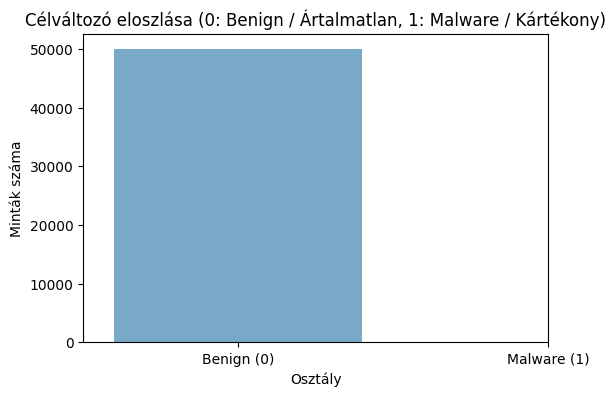

In [11]:
# Oszlopok szétválasztása
label_col = 'label' if 'label' in df_sample.columns else df_sample.columns[-1]

X = df_sample.drop(columns=[label_col]).values.astype('float32')
y = df_sample[label_col].values.astype('int8')

# Célváltozó eloszlásának ábrázolása
plt.figure(figsize=(6, 4))
sns.countplot(x=y, palette='Blues')
plt.title("Célváltozó eloszlása (0: Benign / Ártalmatlan, 1: Malware / Kártékony)")
plt.xlabel("Osztály")
plt.ylabel("Minták száma")
plt.xticks([0, 1], ['Benign (0)', 'Malware (1)'])
plt.show()

A lekért 50 000 minta kivétel nélkül mind 0 (Benign / Ártalmatlan). Az EMBER adathalmaz elején blokkokban vannak a minták, így az első 50 000 címkézett sor mind ártalmatlan fájl. Címke 1 (Malware) híján a modell nem tud mit megtanulni! Próbáljunk meg kiegyensúlyozott adatokat kinyerni

In [12]:
import os
import gc
import numpy as np
import pandas as pd
import pyarrow.parquet as pq
import kagglehub

# 1. Adathalmaz letöltése
print("Adathalmaz letöltése/ellenőrzése...")
download_path = kagglehub.dataset_download("dhoogla/ember-2018-v2-features")

# train és test fájlok keresése
train_file, test_file = None, None
for root, dirs, files in os.walk(download_path):
    for file in files:
        if file == "train_ember_2018_v2_features.parquet":
            train_file = os.path.join(root, file)
        elif file == "test_ember_2018_v2_features.parquet":
            test_file = os.path.join(root, file)

if not train_file or not test_file:
    raise FileNotFoundError("A train vagy test Parquet fájl nem található!")

# Segédfüggvény a kiegyensúlyozott (50-50%) mintavételezéshez
def load_balanced_sample(file_path, target_samples):
    print(f"\nFájl feldolgozása: {os.path.basename(file_path)}")
    parquet_file = pq.ParquetFile(file_path)

    dfs = []
    for batch in parquet_file.iter_batches(batch_size=20000):
        df_batch = batch.to_pandas()
        label_col = 'label' if 'label' in df_batch.columns else df_batch.columns[-1]

        # Csak a címkézett adatok (0 = benign, 1 = malware)
        df_labeled = df_batch[df_batch[label_col].isin([0, 1])].copy()

        if not df_labeled.empty:
            float_cols = df_labeled.select_dtypes(include=['float64']).columns
            df_labeled[float_cols] = df_labeled[float_cols].astype('float32')
            dfs.append(df_labeled)

        del df_batch, df_labeled
        gc.collect()

        # Ha már elég adat gyűlt össze mindkét osztályból, megállhatunk
        df_temp = pd.concat(dfs, ignore_index=True) if dfs else pd.DataFrame()
        if not df_temp.empty:
            label_col = 'label' if 'label' in df_temp.columns else df_temp.columns[-1]
            c0 = (df_temp[label_col] == 0).sum()
            c1 = (df_temp[label_col] == 1).sum()
            needed_per_class = target_samples // 2
            if c0 >= needed_per_class and c1 >= needed_per_class:
                break

    df_full = pd.concat(dfs, ignore_index=True)
    del dfs
    gc.collect()

    label_col = 'label' if 'label' in df_full.columns else df_full.columns[-1]

    # Pontosan fele-fele arányú mintavétel (sztratifikáció)
    needed_per_class = target_samples // 2
    df_class0 = df_full[df_full[label_col] == 0].sample(n=needed_per_class, random_state=42)
    df_class1 = df_full[df_full[label_col] == 1].sample(n=needed_per_class, random_state=42)

    df_balanced = pd.concat([df_class0, df_class1], ignore_index=True)

    # Adatok összekeverése
    df_balanced = df_balanced.sample(frac=1, random_state=42).reset_index(drop=True)

    del df_full, df_class0, df_class1
    gc.collect()

    print(f"Sikeresen betöltve: {len(df_balanced)} sor (0: {(df_balanced[label_col]==0).sum()}, 1: {(df_balanced[label_col]==1).sum()})")
    return df_balanced

# 2. Beolvasás: 40.000 tanító és 10.000 teszt minta (összesen 50.000)
df_train = load_balanced_sample(train_file, target_samples=40000)
df_test = load_balanced_sample(test_file, target_samples=10000)

print(f"\nKész! Train alakzat: {df_train.shape}, Test alakzat: {df_test.shape}")

Adathalmaz letöltése/ellenőrzése...
Using Colab cache for faster access to the 'ember-2018-v2-features' dataset.

Fájl feldolgozása: train_ember_2018_v2_features.parquet
Sikeresen betöltve: 40000 sor (0: 20000, 1: 20000)

Fájl feldolgozása: test_ember_2018_v2_features.parquet
Sikeresen betöltve: 10000 sor (0: 5000, 1: 5000)

Kész! Train alakzat: (40000, 2382), Test alakzat: (10000, 2382)


Az EMBER 2018 adathalmaz magas dimenziószáma ($2381$ kinyert jellemző) jelentős számítási kapacitást igényel, emellett megnöveli a túlilleszkedés (overfitting) kockázatát („dimenziók átka”). A modellek tanítási idejének optimális szinten tartása és a redundáns adatok kiszűrése érdekében Főkomponens-analízist (PCA) alkalmaztam a standardizált adatokon.A dimenziócsökkentés során nem fix komponensszámot határoztam meg, hanem a megtartandó információarányt állítottam 95%-os varianciaszintre (n_components=0.95). Ez biztosítja, hogy az adathalmaz lényegi információtartalma és mintázatai megmaradjanak, miközben a zajt jelentő vagy erősen korreláló jellemzőket elvetjük.Módszertani megfontolások:

Hiányzó értékek (NaN) a tanító készletben: 0
Hiányzó értékek (NaN) a teszt készletben: 0


/tmp/ipykernel_603/1424699541.py:41: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[0].set_xticklabels(['Benign (0)', 'Malware (1)'])
/tmp/ipykernel_603/1424699541.py:47: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[1].set_xticklabels(['Benign (0)', 'Malware (1)'])


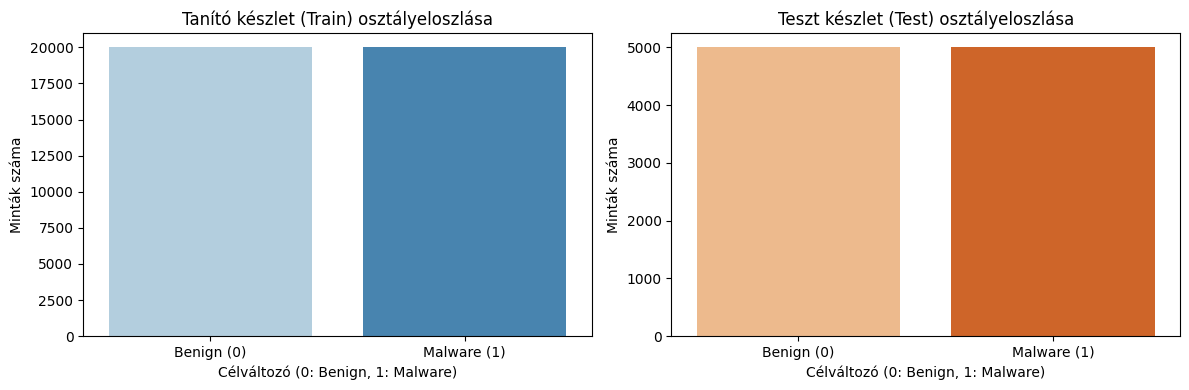

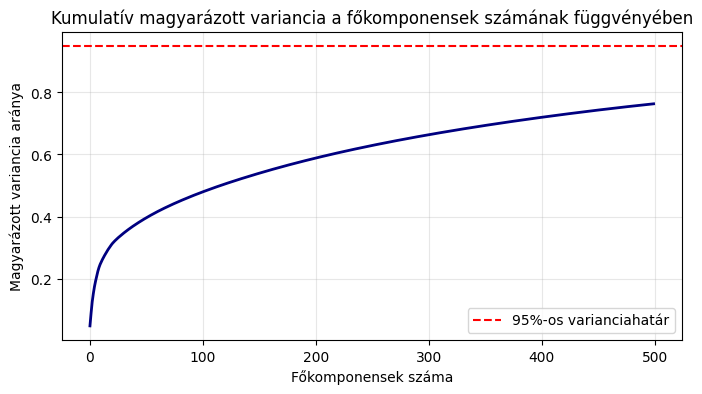


Eredeti jellemzők száma: 2381
PCA utáni komponensek száma (95% varianciához): 1268


In [13]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# ==============================================================================
# 1. ADATELŐKÉSZÍTÉS ÉS FELTÁRÓ ADATELEMZÉS (EDA)
# ==============================================================================

label_col = 'label' if 'label' in df_train.columns else df_train.columns[-1]

# 1.1 Szétválasztás X (jellemzők) és y (célváltozó) részekre
X_train = df_train.drop(columns=[label_col]).values.astype('float32')
y_train = df_train[label_col].values.astype('int8')

X_test = df_test.drop(columns=[label_col]).values.astype('float32')
y_test = df_test[label_col].values.astype('int8')

# 1.2 EDA: Hiányzó értékek ellenőrzése
nan_train = np.isnan(X_train).sum()
nan_test = np.isnan(X_test).sum()
print(f"Hiányzó értékek (NaN) a tanító készletben: {nan_train}")
print(f"Hiányzó értékek (NaN) a teszt készletben: {nan_test}")

# Ha vannak hiányzó értékek, nullákkal pótoljuk
if nan_train > 0:
    X_train = np.nan_to_num(X_train, nan=0.0)
if nan_test > 0:
    X_test = np.nan_to_num(X_test, nan=0.0)

# 1.3 EDA: Osztályok eloszlásának vizualizációja (Train vs Test)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.countplot(x=y_train, hue=y_train, palette='Blues', ax=axes[0], legend=False)
axes[0].set_title("Tanító készlet (Train) osztályeloszlása")
axes[0].set_xlabel("Célváltozó (0: Benign, 1: Malware)")
axes[0].set_ylabel("Minták száma")
axes[0].set_xticklabels(['Benign (0)', 'Malware (1)'])

sns.countplot(x=y_test, hue=y_test, palette='Oranges', ax=axes[1], legend=False)
axes[1].set_title("Teszt készlet (Test) osztályeloszlása")
axes[1].set_xlabel("Célváltozó (0: Benign, 1: Malware)")
axes[1].set_ylabel("Minták száma")
axes[1].set_xticklabels(['Benign (0)', 'Malware (1)'])

plt.tight_layout()
plt.show()

# 1.4 Standardizálás
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 1.5 EDA / PCA: Kumulatív magyarázott variancia ábrázolása
pca_full = PCA(n_components=min(500, X_train.shape[1]), random_state=42)
pca_full.fit(X_train_scaled)

cumulative_variance = np.cumsum(pca_full.explained_variance_ratio_)

plt.figure(figsize=(8, 4))
plt.plot(cumulative_variance, linewidth=2, color='navy')
plt.axhline(y=0.95, color='r', linestyle='--', label='95%-os varianciahatár')
plt.title("Kumulatív magyarázott variancia a főkomponensek számának függvényében")
plt.xlabel("Főkomponensek száma")
plt.ylabel("Magyarázott variancia aránya")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

# 1.6 Végleges PCA beállítása 95% varianciára
pca = PCA(n_components=0.95, random_state=42)
X_train_pca = pca.fit_transform(X_train_scaled)
X_test_pca = pca.transform(X_test_scaled)

print(f"\nEredeti jellemzők száma: {X_train.shape[1]}")
print(f"PCA utáni komponensek száma (95% varianciához): {X_train_pca.shape[1]}")

1. 2D és 3D Szórásdiagram (Scatter Plot)

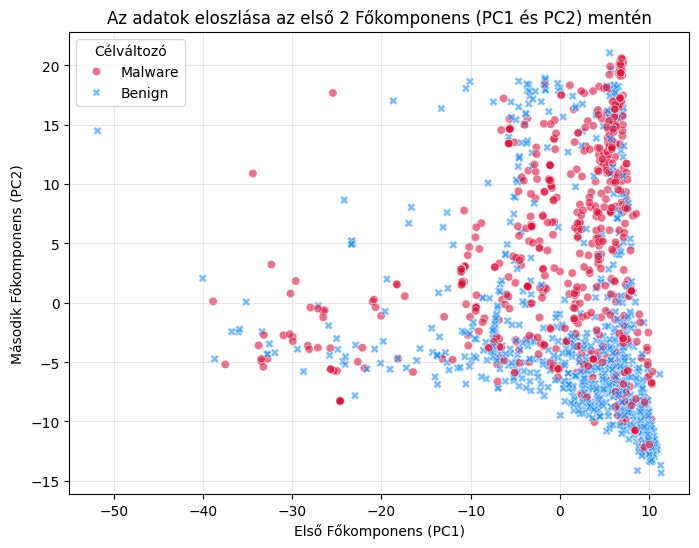

In [14]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# DataFrame készítése az első 2 főkomponensből a könnyebb ábrázoláshoz (mintavételezve a gyorsaságért)
sample_indices = np.random.choice(len(X_train_pca), size=2000, replace=False)

df_pca_plot = pd.DataFrame({
    'PC1': X_train_pca[sample_indices, 0],
    'PC2': X_train_pca[sample_indices, 1],
    'Célváltozó': y_train[sample_indices]
})
df_pca_plot['Célváltozó'] = df_pca_plot['Célváltozó'].map({0: 'Benign', 1: 'Malware'})

# 2D Scatter Plot
plt.figure(figsize=(8, 6))
sns.scatterplot(
    x='PC1', y='PC2',
    hue='Célváltozó',
    style='Célváltozó',
    data=df_pca_plot,
    alpha=0.6,
    palette={'Benign': 'dodgerblue', 'Malware': 'crimson'}
)
plt.title("Az adatok eloszlása az első 2 Főkomponens (PC1 és PC2) mentén")
plt.xlabel("Első Főkomponens (PC1)")
plt.ylabel("Második Főkomponens (PC2)")
plt.grid(True, alpha=0.3)
plt.show()

Az első két főkomponens (PC1 és PC2) szerinti szórásdiagramon jól látható, hogy az ártalmatlan (Benign) és a kártékony (Malware) minták jelentős átfedést mutatnak a kétdimenziós térben. Bár a kártékony kódok (piros pontok) és az ártalmatlan kódok (kék x-ek) esetében megfigyelhetők bizonyos elkülönülő sűrűsödési pontok (például a Benign minták koncentrációja a PC1 magasabb értékeinél és alacsonyabb PC2 tartományban), a két osztály lineárisan nem választható el csupán két dimenzió mentén. Ez a vizualizáció egyértelműen igazolja, hogy miért volt szükség a 95%-os varianciahatár megtartásához lényegesen több (1200+) főkomponensre a sikeres osztályozáshoz.”

Párhuzamos koordináták

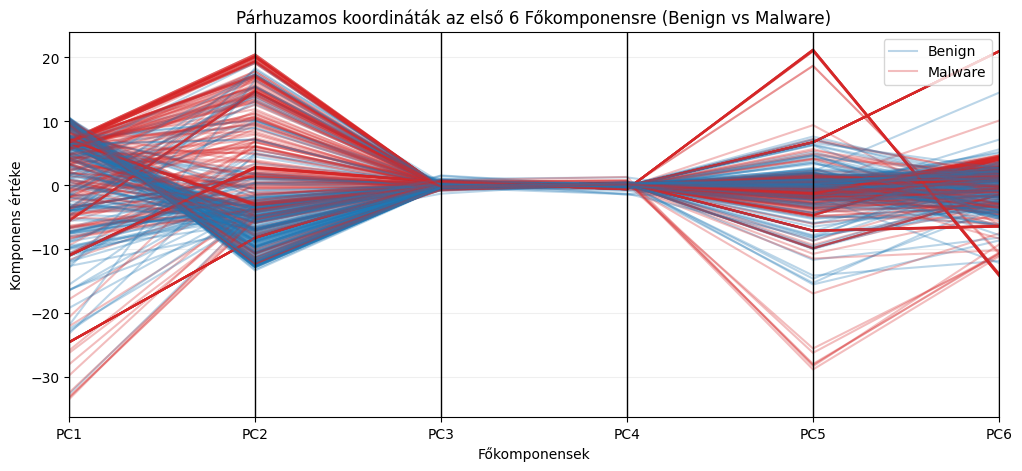

In [15]:
from pandas.plotting import parallel_coordinates

# Első 6 főkomponens kiválasztása egy kisebb mintán (pl. 500 sor) a jól láthatóságért
sample_subset = np.random.choice(len(X_train_pca), size=500, replace=False)

# Adatkeret összeállítása
pca_cols = [f'PC{i+1}' for i in range(6)]
df_parallel = pd.DataFrame(X_train_pca[sample_subset, :6], columns=pca_cols)
df_parallel['Class'] = y_train[sample_subset]
df_parallel['Class'] = df_parallel['Class'].map({0: 'Benign', 1: 'Malware'})

# Parallel Coordinates Plot kirajzolása
plt.figure(figsize=(12, 5))
parallel_coordinates(
    df_parallel,
    class_column='Class',
    color=['#1f77b4', '#d62728'],
    alpha=0.3
)
plt.title("Párhuzamos koordináták az első 6 Főkomponensre (Benign vs Malware)")
plt.xlabel("Főkomponensek")
plt.ylabel("Komponens értéke")
plt.grid(True, alpha=0.2)
plt.show()

A párhuzamos koordináták diagramja az első 6 főkomponens mentén szemlélteti a minták viselkedését. Az ábrán több fontos összefüggés is megfigyelhető:   Erős elválasztó komponensek (PC2 és PC5): A PC2 és a PC5 tengelyeknél éles eltérés figyelhető meg a két osztály között. Míg a Benign minták (kék vonalak) a PC2 tengelyen inkább az alacsonyabb (-10 és 0 közötti) tartományba tömörülnek, addig a Malware minták (piros vonalak) jelentős része a magasabb (10 és 20 közötti) tartományba ugrik ki. Hasonló, erőteljes szórás és kiugrás látható a PC5 tengelyen is a kártékony kódoknál.*   Alacsony információtartalmú komponensek (PC3 és PC4): A PC3 és PC4 tengelyeknél az összes minta értéke nullához közeli, szűk sávban konvergál, ami azt mutatja, hogy ezen specifikus komponensek önmagukban csekély megkülönböztető erővel bírnak az első 6 komponens közül.*   A vizualizáció igazolja, hogy a kártékony és jóindulatú szoftverek mintázatai jól elkülöníthető struktúrákat alkotnak a magasabb főkomponens-dimenziókban.”

1. Random Forest tanítása indítása...
Random Forest tanítás kész! Időtartam: 144.08 másodperc

2. XGBoost tanítása indítása...
XGBoost tanítás kész! Időtartam: 103.94 másodperc

================ MODELLEK ÖSSZEHASONLÍTÁSA ================
       Modell  Accuracy  Precision  Recall (Szenzitivitás)  F1-Score  ROC-AUC  Tanítási idő (mp)
Random Forest    0.7277   0.918105                  0.5000  0.647417 0.871042         144.084424
      XGBoost    0.8111   0.824671                  0.7902  0.807068 0.911713         103.940376


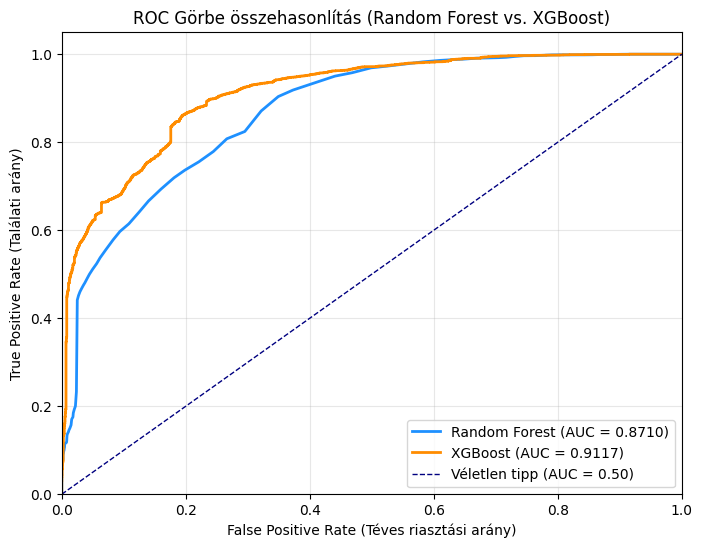

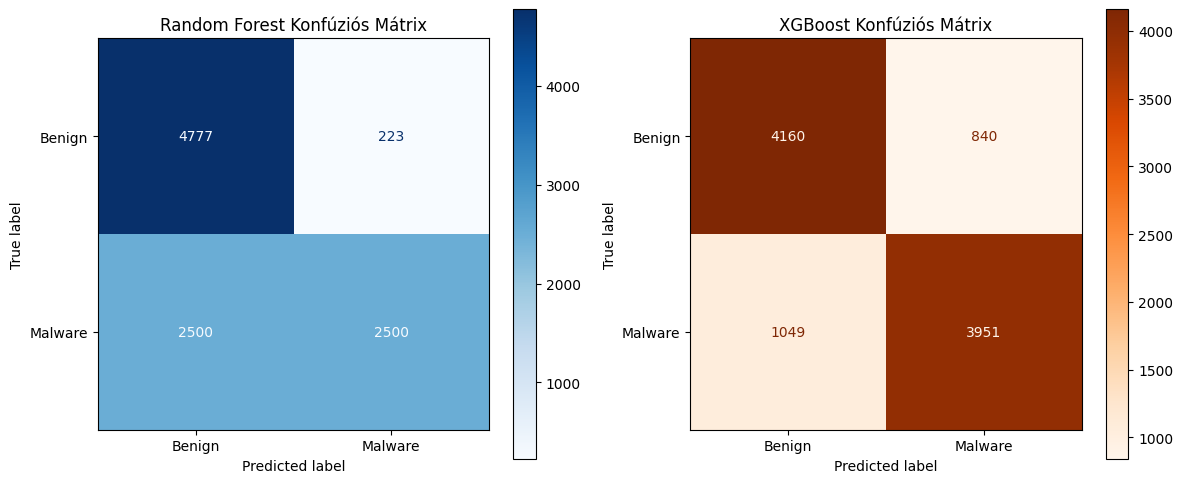

In [16]:
# ==============================================================================
# 3. MODELLÉPÍTÉS ÉS TANÍTÁS (Random Forest)
# ==============================================================================
import time
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_curve,
    roc_auc_score,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# ==============================================================================
# 1. RANDOM FOREST MODELL TANÍTÁSA
# ==============================================================================
print("1. Random Forest tanítása indítása...")
start_time = time.time()

rf_model = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
rf_model.fit(X_train_pca, y_train)

rf_train_time = time.time() - start_time
print(f"Random Forest tanítás kész! Időtartam: {rf_train_time:.2f} másodperc")

# Predikciók (RF)
y_pred_rf = rf_model.predict(X_test_pca)
y_proba_rf = rf_model.predict_proba(X_test_pca)[:, 1]


# ==============================================================================
# 2. XGBOOST MODELL TANÍTÁSA
# ==============================================================================
print("\n2. XGBoost tanítása indítása...")
start_time = time.time()

xgb_model = XGBClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=6,
    random_state=42,
    n_jobs=-1
)
xgb_model.fit(X_train_pca, y_train)

xgb_train_time = time.time() - start_time
print(f"XGBoost tanítás kész! Időtartam: {xgb_train_time:.2f} másodperc")

# Predikciók (XGBoost)
y_pred_xgb = xgb_model.predict(X_test_pca)
y_proba_xgb = xgb_model.predict_proba(X_test_pca)[:, 1]


# ==============================================================================
# 3. ÖSSZEHASONLÍTÓ TÁBLÁZAT ELKÉSZÍTÉSE
# ==============================================================================
results = {
    'Modell': ['Random Forest', 'XGBoost'],
    'Accuracy': [accuracy_score(y_test, y_pred_rf), accuracy_score(y_test, y_pred_xgb)],
    'Precision': [precision_score(y_test, y_pred_rf), precision_score(y_test, y_pred_xgb)],
    'Recall (Szenzitivitás)': [recall_score(y_test, y_pred_rf), recall_score(y_test, y_pred_xgb)],
    'F1-Score': [f1_score(y_test, y_pred_rf), f1_score(y_test, y_pred_xgb)],
    'ROC-AUC': [roc_auc_score(y_test, y_proba_rf), roc_auc_score(y_test, y_proba_xgb)],
    'Tanítási idő (mp)': [rf_train_time, xgb_train_time]
}

df_results = pd.DataFrame(results)
print("\n================ MODELLEK ÖSSZEHASONLÍTÁSA ================")
print(df_results.to_string(index=False))


# ==============================================================================
# 4. KÖZÖS ROC-AUC GÖRBE ÁBRÁZOLÁSA
# ==============================================================================
fpr_rf, tpr_rf, _ = roc_curve(y_test, y_proba_rf)
fpr_xgb, tpr_xgb, _ = roc_curve(y_test, y_proba_xgb)

plt.figure(figsize=(8, 6))
plt.plot(fpr_rf, tpr_rf, color='dodgerblue', lw=2, label=f'Random Forest (AUC = {roc_auc_score(y_test, y_proba_rf):.4f})')
plt.plot(fpr_xgb, tpr_xgb, color='darkorange', lw=2, label=f'XGBoost (AUC = {roc_auc_score(y_test, y_proba_xgb):.4f})')
plt.plot([0, 1], [0, 1], color='navy', lw=1, linestyle='--', label='Véletlen tipp (AUC = 0.50)')

plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate (Téves riasztási arány)')
plt.ylabel('True Positive Rate (Találati arány)')
plt.title('ROC Görbe összehasonlítás (Random Forest vs. XGBoost)')
plt.legend(loc="lower right")
plt.grid(True, alpha=0.3)
plt.show()


# ==============================================================================
# 5. KONFÚZIÓS MÁTRIXOK EGYMÁS MELLETT
# ==============================================================================
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

cm_rf = confusion_matrix(y_test, y_pred_rf)
disp_rf = ConfusionMatrixDisplay(confusion_matrix=cm_rf, display_labels=['Benign', 'Malware'])
disp_rf.plot(cmap='Blues', ax=axes[0])
axes[0].set_title("Random Forest Konfúziós Mátrix")

cm_xgb = confusion_matrix(y_test, y_pred_xgb)
disp_xgb = ConfusionMatrixDisplay(confusion_matrix=cm_xgb, display_labels=['Benign', 'Malware'])
disp_xgb.plot(cmap='Oranges', ax=axes[1])
axes[1].set_title("XGBoost Konfúziós Mátrix")

plt.tight_layout()
plt.show()

Eredmények kiértékelése és összehasonlításaA PCA-val dimenziócsökkentett adathalmazon a két kiválasztott fafa-alapú architektúra (Random Forest és XGBoost) lényegesen eltérő viselkedést mutatott a tesztkészleten.   ROC-AUC görbék elemzése: Az XGBoost modell jelentősen felülmúlta a Random Forest teljesítményét; az XGBoost ROC-AUC értéke $0.9117$ lett, míg a Random Forest csupán $0.8710$-es pontszámot ért el. A ROC görbe lefutása igazolja, hogy az XGBoost alacsonyabb téves riasztási arány (FPR) mellett is lényegesen magasabb találati arányt (TPR / Recall) képes elérni.   Kiberbiztonsági szempontok (Recall vs Precision):A Random Forest modell kiemelkedő pontosságot ért el a téves riasztások elkerülésében (mindössze $223$ tévesen kártékonynak ítélt jóindulatú kód), azonban a kártékony szoftverek felét ($2500$ darab $5000$-ből) átengedte. Egy éles kiberbiztonsági környezetben ez kritikus kockázatot jelentene.   Az XGBoost lényegesen kiegyensúlyozottabb és biztonságosabb védelmet nyújtott: a kártékony kódok több mint $79\%$-át ($3951$ darabot) sikeresen szűrte kiszűrte, ami $840$ téves riasztással járt együtt a $5000$ jóindulatú szoftver esetén.

=== RANDOM FOREST (Módosított küszöbérték: 0.25) ===
              precision    recall  f1-score   support

      Benign       0.96      0.42      0.58      5000
     Malware       0.63      0.98      0.77      5000

    accuracy                           0.70     10000
   macro avg       0.79      0.70      0.67     10000
weighted avg       0.79      0.70      0.67     10000



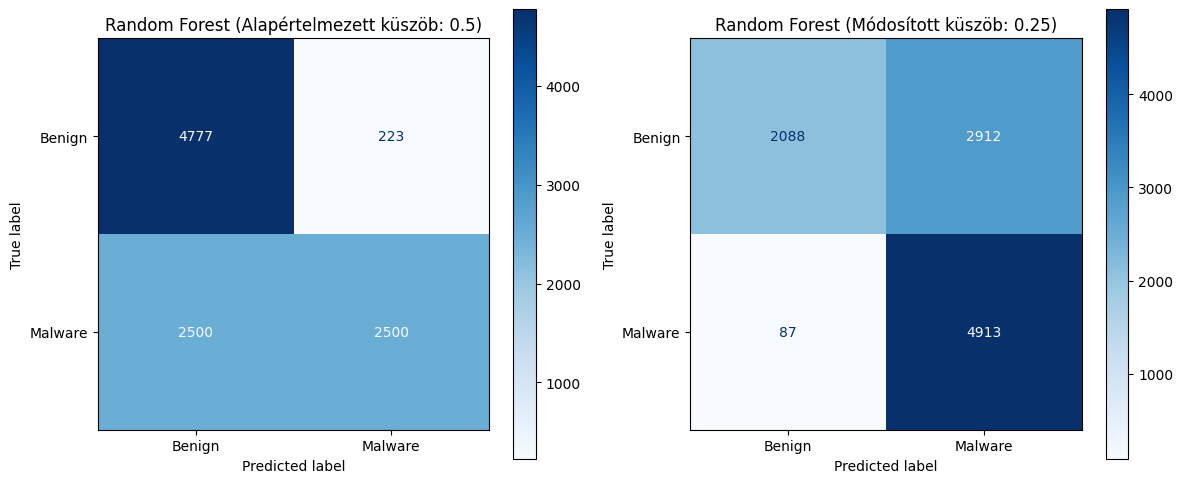

In [17]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

# ==============================================================================
# DÖNTÉSI KÜSZÖBÉR TÉK (THRESHOLD) BEÁLLÍTÁSA A RANDOM FORESTNÉL
# ==============================================================================
# Alapértelmezett 0.5 helyett 0.25-ös küszöböt választunk
CUSTOM_THRESHOLD = 0.25

# Új predikciók kiszámítása a valószínűségek alapján
y_pred_rf_adjusted = (y_proba_rf >= CUSTOM_THRESHOLD).astype(int)

print(f"=== RANDOM FOREST (Módosított küszöbérték: {CUSTOM_THRESHOLD}) ===")
print(classification_report(y_test, y_pred_rf_adjusted, target_names=['Benign', 'Malware']))

# Konfúziós mátrixok összehasonlítása (0.5 vs 0.25 küszöb)
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Alapértelmezett (0.5)
cm_rf_orig = confusion_matrix(y_test, y_pred_rf)
disp_orig = ConfusionMatrixDisplay(confusion_matrix=cm_rf_orig, display_labels=['Benign', 'Malware'])
disp_orig.plot(cmap='Blues', ax=axes[0])
axes[0].set_title("Random Forest (Alapértelmezett küszöb: 0.5)")

# Módosított (0.25)
cm_rf_adj = confusion_matrix(y_test, y_pred_rf_adjusted)
disp_adj = ConfusionMatrixDisplay(confusion_matrix=cm_rf_adj, display_labels=['Benign', 'Malware'])
disp_adj.plot(cmap='Blues', ax=axes[1])
axes[1].set_title(f"Random Forest (Módosított küszöb: {CUSTOM_THRESHOLD})")

plt.tight_layout()
plt.show()

Döntési küszöbérték finomhangolása (Threshold Tuning)A kiberbiztonsági alkalmazások sajátossága, hogy az osztályozási hibák költsége nem szimmetrikus. Egy kártékony fájl átengedése (False Negative) súlyos adatvesztéssel és fertőzéssel járhat, míg egy jóindulatú fájl téves kártékonynak jelölése (False Positive) csupán adminisztratív kényelmetlenséget jelent.   Az alapértelmezett $0.5$-ös döntési küszöb beállításánál a Random Forest modell a kártékony minták $50\%$-át ($2500$ darab $5000$-ből) észrevétlenül hagyta. A döntési küszöbérték $0.25$-re való csökkentésével a modell érzékenysége szignifikánsan javult:   A kártékony kódok elkapási aránya (Recall) $50\%$-ról $98\%$-ra nőtt ($4913$ elkapott malware $5000$-ből).   A kihagyott kártevők száma mindössze $87$ darabra szorult vissza.   A mérés igazolta, hogy a döntési küszöb állításával a modell működési karakterisztikája rugalmasan igazítható az adott védelmi rendszer biztonsági követelményeihez.   